# Violência sexual contra meninas e mulheres no Brasil: o que revelam os registros de saúde e de polícia

**Análise Exploratória de Dados e Visualização** · Prof. João Rulff · FGV EMAp · 2026.2
Fabrício Rafael da Mata Aguiar, Gabrielle Eduarda Azevedo, Laura Varaldo Oliveira

Repositório: https://github.com/gabrielleazev/aedv-violencia-sexual

## Introdução


## Dados

**SINAN (Ministério da Saúde):** notificações de violência interpessoal, 2015–2024, baixadas com a biblioteca PySUS (ver `notebooks/00_download_sinan.ipynb`). Filtramos as notificações com violência sexual (`VIOL_SEXU = 1`) e vítima do sexo feminino (`CS_SEXO = F`).

**População:** estimativas de população feminina por UF e por faixa etária, 2015–2024, Ministério da Saúde (TabNet). Para cor/raça e deficiência, que não existem nessas estimativas, usamos o Censo Demográfico 2022 do IBGE (SIDRA, tabela 9606, para população feminina por cor ou raça; e a divulgação dos resultados sobre pessoas com deficiência).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

sinan = pd.read_parquet("../data/processed/sinan_violencia_sexual_f_2015_2024.parquet")
print(sinan.shape)
sinan.head()

(433517, 160)


,TP_NOT,ID_AGRAVO,DT_NOTIFIC,SEM_NOT,NU_ANO,SG_UF_NOT,ID_MUNICIP,DT_OCOR,SEM_PRI,ANO_NASC,...,DELEG_IDOS,DIR_HUMAN,MPU,DELEG_CRIA,DELEG_MULH,DELEG,INFAN_JUV,DEFEN_PUBL,DT_ENCERRA,ANO_ARQUIVO
0,2,Y09,20150720,201529,2015,35,3510609,20150720,201529,2006,...,2,2,2,2,1,2,2,2,20150819,2015
1,2,Y09,20150826,201534,2015,33,3301702,20150826,201534,2005,...,2,2,2,2,2,2,2,2,20150826,2015
2,2,Y09,20150714,201528,2015,26,2606002,20150714,201528,2005,...,2,2,2,2,2,2,2,2,20150715,2015
3,2,Y09,20150317,201511,2015,13,1302504,20150317,201508,2006,...,2,2,2,2,2,2,2,2,20150317,2015
4,2,Y09,20150407,201514,2015,42,4205407,20150407,201514,2006,...,2,2,2,2,2,2,2,2,20150407,2015


### Limpeza e padronização

Convertemos os tipos (ano, data), decodificamos a idade (no SINAN, o primeiro dígito indica a unidade: 4 = anos), traduzimos os códigos de raça/cor e deficiência e medimos a proporção de campos ignorados ou vazios, que afeta a confiabilidade de cada análise.

In [2]:
import numpy as np

def limpa_codigo(col):
    # "1.0" -> "1", "nan" -> vazio
    return col.astype(str).str.replace(r"\.0$", "", regex=True).replace({"nan": np.nan, "None": np.nan})

# ano e data
sinan["ANO"] = sinan["ANO_ARQUIVO"].astype(int)
sinan["DT_OCOR"] = pd.to_datetime(sinan["DT_OCOR"], errors="coerce", format="mixed")

# idade
idade_cod = pd.to_numeric(sinan["NU_IDADE_N"], errors="coerce")
if idade_cod.max() > 200:
    unidade, valor = idade_cod // 1000, idade_cod % 1000
    sinan["IDADE"] = np.where(unidade == 4, valor, np.where(unidade.isin([1, 2, 3]), 0, np.nan))
else:
    sinan["IDADE"] = idade_cod
sinan.loc[sinan["IDADE"] > 110, "IDADE"] = np.nan   # idades impossíveis

sinan["FAIXA"] = pd.cut(sinan["IDADE"], bins=[-1, 13, 17, 120],
                        labels=["0 a 13 anos", "14 a 17 anos", "18 anos ou mais"])

# raça/cor e deficiência
sinan["RACA"] = limpa_codigo(sinan["CS_RACA"]).map(
    {"1": "Branca", "2": "Preta", "3": "Amarela", "4": "Parda", "5": "Indígena"}).fillna("Ignorado")
sinan["DEFICIENCIA"] = limpa_codigo(sinan["DEF_TRANS"]).map(
    {"1": "Sim", "2": "Não"}).fillna("Ignorado")

# qualidade do preenchimento
qualidade = pd.Series({
    "Data da ocorrência": sinan["DT_OCOR"].isna().mean() * 100,
    "Idade": sinan["IDADE"].isna().mean() * 100,
    "Raça/cor": (sinan["RACA"] == "Ignorado").mean() * 100,
    "Deficiência": (sinan["DEFICIENCIA"] == "Ignorado").mean() * 100,
}).round(1)
qualidade.to_frame("% ignorado ou vazio")

,% ignorado ou vazio
Data da ocorrência,0.0
Idade,0.1
Raça/cor,5.7
Deficiência,11.5


## 1. Como os registros evoluíram de 2015 a 2024, e o que mudou durante a pandemia?

**Pergunta de dados:** qual a taxa anual de notificações de violência sexual contra meninas e mulheres por 100 mil mulheres, de 2015 a 2024?

**Transformação:** contamos as notificações por ano, juntamos com a população feminina do mesmo ano e calculamos a taxa (notificações ÷ população × 100 mil).

In [3]:
# casos por ano
por_ano = sinan["ANO_ARQUIVO"].astype(int).value_counts().sort_index()
por_ano

ANO_ARQUIVO
2015    24393
2016    27354
2017    33028
2018    36891
2019    40451
2020    35210
2021    42106
2022    50996
2023    69450
2024    73638
Name: count, dtype: int64

In [4]:
pop_uf = pd.read_csv(
    "../data/processed/pop_feminina_uf_2015_2024.csv",
    sep=";", encoding="latin-1", skiprows=4
)

# mantém só as linhas dos estados ("11 Rondônia"...) e a linha Total
primeira_col = pop_uf.columns[0]
pop_uf = pop_uf[pop_uf[primeira_col].str.match(r"^\d{2} |^Total", na=False)]
pop_uf = pop_uf.rename(columns={primeira_col: "UF"})

# converte os anos para número
anos = [str(a) for a in range(2015, 2025)]
pop_uf[anos] = pop_uf[anos].astype(int)

pop_uf

,UF,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,11 Rondônia,823859,830690,836728,842204,847870,853458,857719,861124,864583,868133
1,12 Acre,411807,416618,420751,424282,427514,430469,432894,434993,436943,438884
2,13 Amazonas,1919387,1946666,1972066,1997414,2024152,2048341,2068548,2088745,2109003,2129205
3,14 Roraima,264285,271147,278905,290159,304699,315780,322900,332008,342577,352946
4,15 Pará,4040935,4079424,4113792,4145850,4178794,4210629,4239966,4265962,4289392,4313795
5,16 Amapá,372653,377575,381877,385476,388806,391956,394822,397233,399205,401255
6,17 Tocantins,725946,733236,740135,747064,754167,761101,767204,772489,777887,783522
7,21 Maranhão,3448611,3466600,3481536,3496284,3512440,3526357,3537244,3544278,3548427,3553820
8,22 Piauí,1659286,1667619,1675605,1684307,1693536,1701793,1708534,1713847,1718885,1724357
9,23 Ceará,4529007,4558855,4585717,4612952,4643029,4671192,4693811,4712189,4730055,4749310


In [5]:
# população feminina do Brasil por ano (linha Total)
pop_brasil = pop_uf[pop_uf["UF"] == "Total"][anos].iloc[0]
pop_brasil.index = pop_brasil.index.astype(int)

taxa = (por_ano / pop_brasil * 100_000).round(1)

tabela_p1 = pd.DataFrame({
    "notificacoes": por_ano,
    "pop_feminina": pop_brasil,
    "taxa_100mil": taxa
})
tabela_p1

,notificacoes,pop_feminina,taxa_100mil
2015,24393,103476277,23.6
2016,27354,104241004,26.2
2017,33028,104943736,31.5
2018,36891,105633483,34.9
2019,40451,106348865,38.0
2020,35210,107023935,32.9
2021,42106,107552789,39.1
2022,50996,107987869,47.2
2023,69450,108443605,64.0
2024,73638,108921464,67.6


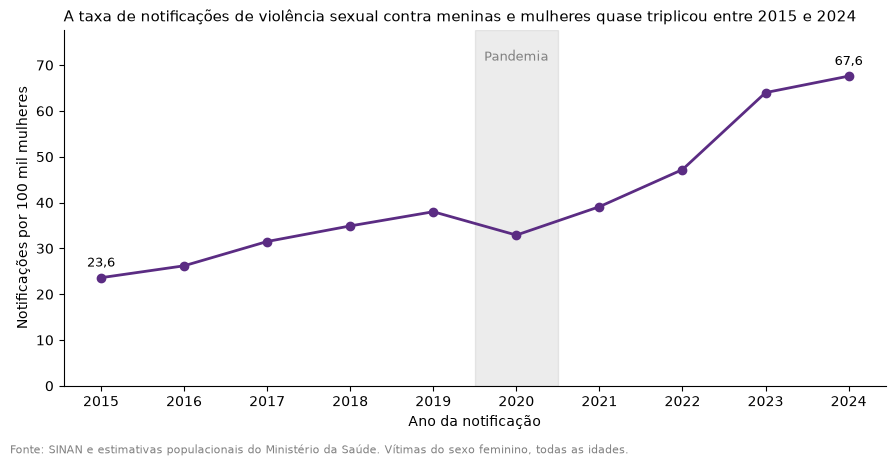

Taxa 2015: 23.6  |  Taxa 2024: 67.6  |  aumento: 2.9x
Variação 2019 → 2020: -13.4%


In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(taxa.index, taxa.values, marker="o", color="#5B2C83", linewidth=2)

# destaque da pandemia
ax.axvspan(2019.5, 2020.5, color="gray", alpha=0.15)
ax.text(2020, taxa.max() * 1.05, "Pandemia", ha="center", fontsize=9, color="gray")

# valor no primeiro e no último ano
for ano in [2015, 2024]:
    ax.annotate(f"{taxa[ano]:.1f}".replace(".", ","), (ano, taxa[ano]),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)

ax.set_title("A taxa de notificações de violência sexual contra meninas e mulheres quase triplicou entre 2015 e 2024",
             fontsize=11, loc="left")
ax.set_xlabel("Ano da notificação")
ax.set_ylabel("Notificações por 100 mil mulheres")
ax.set_xticks(taxa.index)
ax.set_ylim(0, taxa.max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)

fig.text(0.01, -0.02,
         "Fonte: SINAN e estimativas populacionais do Ministério da Saúde. Vítimas do sexo feminino, todas as idades.",
         fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("../figures/p1_taxa_anual.png", dpi=200, bbox_inches="tight")
plt.show()

# números para o texto
print(f"Taxa 2015: {taxa[2015]}  |  Taxa 2024: {taxa[2024]}  |  aumento: {taxa[2024]/taxa[2015]:.1f}x")
print(f"Variação 2019 → 2020: {(taxa[2020]/taxa[2019] - 1)*100:.1f}%")

**O que o gráfico mostra.** Entre 2015 e 2024, a taxa de notificações de violência sexual contra meninas e mulheres no SINAN passou de 23,6 para 67,6 por 100 mil mulheres, um aumento de 2,9 vezes. Como a taxa já desconta o crescimento da população, esse aumento não se explica por haver mais mulheres no país. O crescimento foi contínuo, com uma única interrupção: em 2020, primeiro ano da pandemia de Covid-19, a taxa caiu 13,4% em relação a 2019.

**Como interpretar.** A queda de 2020 não indica necessariamente menos violência: com o isolamento social e os serviços de saúde sobrecarregados, menos vítimas chegaram a um atendimento onde o caso pudesse ser notificado. Em 2021 a taxa já havia superado o patamar pré-pandemia. Da mesma forma, o crescimento ao longo da década mistura dois efeitos que estes dados não permitem separar: o aumento real da violência e a ampliação da capacidade de notificação dos serviços. Os registros policiais (FBSP), analisados na pergunta 7, ajudam a avaliar se a tendência aparece também fora do sistema de saúde.

## 2. Em que meses e dias da semana os casos se concentram? O ritmo é o mesmo para crianças e adultas?

**Pergunta de dados:** como as notificações se distribuem por mês e por dia da semana da ocorrência, separando as vítimas em três faixas etárias (0 a 13, 14 a 17 e 18 anos ou mais)?

**Transformação:** convertemos a data da ocorrência (`DT_OCOR`) em data, extraímos o mês e o dia da semana, e usamos as faixas etárias criadas na limpeza. Como as faixas têm tamanhos muito diferentes, comparamos a **porcentagem** dos casos de cada faixa em cada mês ou dia, e não a contagem. Excluímos as ocorrências registradas em 1º de janeiro: nas vítimas de 0 a 13 anos, 2,56% dos casos tinham essa data, quase dez vezes o esperado se as datas fossem distribuídas igualmente (0,27%). Isso indica que a data costuma ser preenchida por aproximação quando a data real é desconhecida, como em abusos repetidos.

In [7]:
# só ocorrências dentro do período e com data e faixa válidas
p2 = sinan[sinan["DT_OCOR"].dt.year.between(2015, 2024) & sinan["FAIXA"].notna()].copy()
# exclui 1º de janeiro: data usada como preenchimento quando a data real é desconhecida
p2 = p2[~((p2["DT_OCOR"].dt.month == 1) & (p2["DT_OCOR"].dt.day == 1))]

p2["MES"] = p2["DT_OCOR"].dt.month
p2["DIA_SEMANA"] = p2["DT_OCOR"].dt.dayofweek   # 0 = segunda

print(f"Casos usados na P2: {len(p2)} de {len(sinan)} ({len(p2)/len(sinan):.1%})")
p2["FAIXA"].value_counts()

Casos usados na P2: 416001 de 433517 (96.0%)


FAIXA
0 a 13 anos        210819
18 anos ou mais    132729
14 a 17 anos        72453
Name: count, dtype: int64

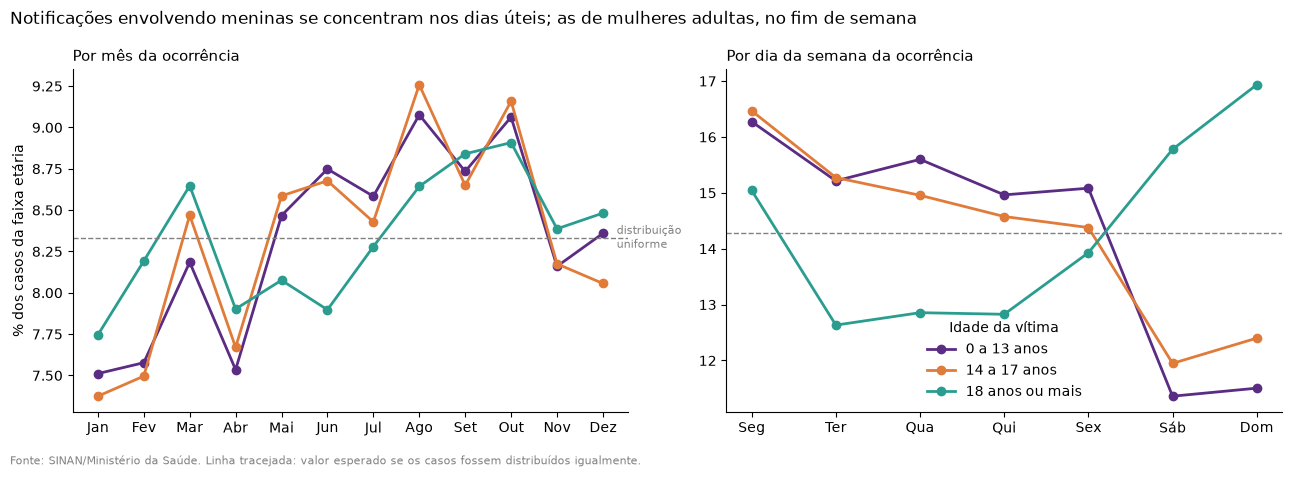

In [8]:
cores = {"0 a 13 anos": "#5B2C83", "14 a 17 anos": "#E07B39", "18 anos ou mais": "#2A9D8F"}
meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]

pct_mes = pd.crosstab(p2["MES"], p2["FAIXA"], normalize="columns") * 100
pct_dia = pd.crosstab(p2["DIA_SEMANA"], p2["FAIXA"], normalize="columns") * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

for faixa, cor in cores.items():
    ax1.plot(pct_mes.index, pct_mes[faixa], marker="o", color=cor, label=faixa, linewidth=2)
    ax2.plot(pct_dia.index, pct_dia[faixa], marker="o", color=cor, label=faixa, linewidth=2)

ax1.set_xticks(range(1, 13), meses)
ax1.set_title("Por mês da ocorrência", loc="left", fontsize=11)
ax1.set_ylabel("% dos casos da faixa etária")
ax1.axhline(100/12, color="gray", linestyle="--", linewidth=1)
ax1.text(12.3, 100/12, "distribuição\nuniforme", fontsize=8, color="gray", va="center")

ax2.set_xticks(range(7), dias)
ax2.set_title("Por dia da semana da ocorrência", loc="left", fontsize=11)
ax2.axhline(100/7, color="gray", linestyle="--", linewidth=1)
ax2.legend(frameon=False, title="Idade da vítima")

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Notificações envolvendo meninas se concentram nos dias úteis; as de mulheres adultas, no fim de semana",
             x=0.01, ha="left", fontsize=12)
fig.text(0.01, -0.03, "Fonte: SINAN/Ministério da Saúde. Linha tracejada: valor esperado se os casos fossem distribuídos igualmente.",
         fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("../figures/p2_mes_dia_semana.png", dpi=200, bbox_inches="tight")
plt.show()

**O que o gráfico mostra.** O dia da semana separa claramente as faixas etárias. Entre mulheres adultas, os casos se concentram no fim de semana: domingo reúne 17% das ocorrências e sábado quase 16%, acima dos 14,3% esperados. Entre meninas de 0 a 13 e de 14 a 17 anos, o padrão se inverte: as ocorrências se concentram nos dias úteis, com pico na segunda-feira, e caem para 11% a 12,5% no fim de semana.

**Como interpretar.** Para as adultas, o padrão é compatível com situações de lazer e convívio social. Para as meninas, ele acompanha o calendário escolar: além da concentração nos dias úteis, os meses com menos notificações são janeiro, fevereiro e abril, com uma queda também em julho, enquanto os picos ocorrem em março, agosto e outubro, logo após o retorno das aulas. Entre as adultas, a variação entre meses é menor e não segue esse calendário. Uma hipótese é que parte da violência contra crianças, frequentemente cometida em casa e de forma repetida, seja registrada na data em que é revelada, muitas vezes por professores ou em serviços ligados à escola, e não na data em que aconteceu. Se for assim, as férias escolares não reduziriam a violência, mas sim a chance de ela ser identificada. Observação: fevereiro tem menos dias que os outros meses, o que explica parte do seu valor mais baixo.

**Cuidado com os dados.** A concentração de datas em 1º de janeiro mostra que a data da ocorrência é menos confiável para crianças, justamente o grupo em que a violência tende a ser contínua.

## 3. Quem são as vítimas? Como as taxas variam por idade, cor/raça e deficiência?

**Pergunta de dados:** qual a idade das vítimas notificadas e qual a taxa de notificação por 100 mil mulheres em cada faixa etária, cor/raça e condição de deficiência?

**Transformação:** usamos a idade decodificada na etapa de limpeza. Primeiro olhamos a distribuição das notificações por idade simples (contagem); depois dividimos pelo tamanho de cada grupo na população para obter taxas. Para idade, usamos as estimativas anuais 2015–2024. Para cor/raça, a população só está disponível no Censo 2022, então comparamos com a média anual de notificações de 2021 a 2023, centrada no ano do Censo.

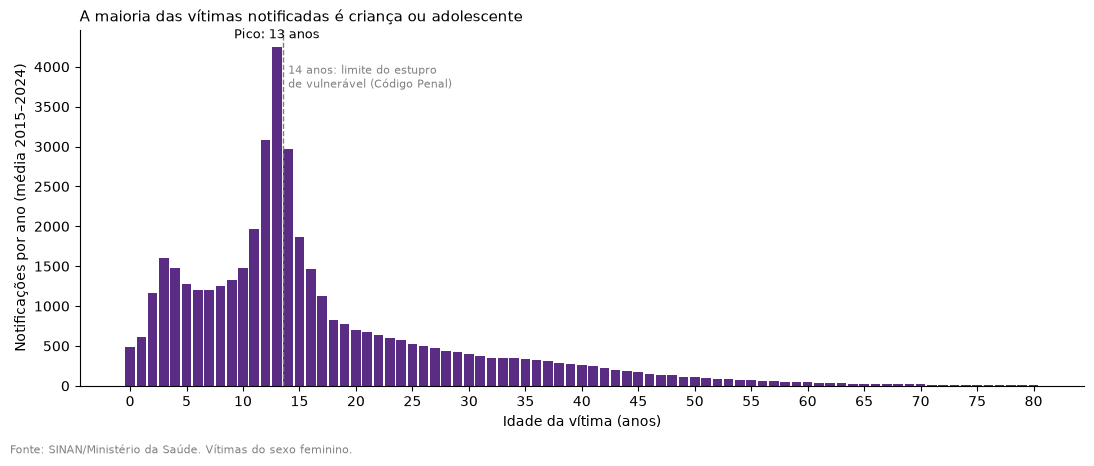

Vítimas com menos de 14 anos: 51.6%  |  com menos de 18: 68.7%


In [9]:
# média anual de notificações por idade simples (0 a 80 anos)
por_idade = (sinan[sinan["IDADE"].between(0, 80)]
             .groupby("IDADE").size() / 10)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(por_idade.index, por_idade.values, color="#5B2C83", width=0.85)

# destaque do limite legal do estupro de vulnerável (< 14 anos)
ax.axvline(13.5, color="gray", linestyle="--", linewidth=1)
ax.text(14, por_idade.max() * 0.95, "14 anos: limite do estupro\nde vulnerável (Código Penal)",
        fontsize=8, color="gray", va="top")

idade_pico = int(por_idade.idxmax())
ax.annotate(f"Pico: {idade_pico} anos", (idade_pico, por_idade.max()),
            textcoords="offset points", xytext=(0, 6), ha="center", fontsize=9)

ax.set_title("A maioria das vítimas notificadas é criança ou adolescente",
             loc="left", fontsize=11)
ax.set_xlabel("Idade da vítima (anos)")
ax.set_ylabel("Notificações por ano (média 2015–2024)")
ax.set_xticks(range(0, 81, 5))
ax.spines[["top", "right"]].set_visible(False)

fig.text(0.01, -0.02, "Fonte: SINAN/Ministério da Saúde. Vítimas do sexo feminino.",
         fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("../figures/p3_idade.png", dpi=200, bbox_inches="tight")
plt.show()

menores_14 = (sinan["IDADE"] < 14).mean() * 100
menores_18 = (sinan["IDADE"] < 18).mean() * 100
print(f"Vítimas com menos de 14 anos: {menores_14:.1f}%  |  com menos de 18: {menores_18:.1f}%")

**O que o gráfico mostra.** Mais da metade das vítimas notificadas (51,6%) tinha menos de 14 anos, e 68,7% eram menores de 18. A idade com mais notificações é 13 anos, logo antes do limite legal do estupro de vulnerável. Há também um segundo pico entre 3 e 4 anos. Depois dos 15 anos, as notificações caem de forma contínua com a idade.

### Taxa por faixa etária

A contagem não leva em conta que cada idade tem um número diferente de mulheres na população. Por isso, dividimos as notificações de cada faixa pela população feminina da mesma faixa. A taxa abaixo é uma média anual: notificações de 2015 a 2024 ÷ população somada dos 10 anos × 100 mil.

In [10]:
pop_idade = pd.read_csv("../data/processed/pop_feminina_idade_2015_2024.csv",
                        sep=";", encoding="latin-1", skiprows=4)
pop_idade = pop_idade.rename(columns={pop_idade.columns[0]: "FAIXA_POP"})
pop_idade = pop_idade[pop_idade["FAIXA_POP"].str.contains("anos", na=False)].copy()
pop_idade["FAIXA_POP"] = pop_idade["FAIXA_POP"].str.strip()
pop_idade["pop_total"] = pop_idade[anos].astype(int).sum(axis=1)   # soma 2015–2024 (ignora 2014)

faixas_pop = pop_idade["FAIXA_POP"].tolist()
sinan["FAIXA_POP"] = pd.cut(sinan["IDADE"], bins=[-1, 4, 9, 14, 19, 29, 39, 49, 59, 69, 79, 200],
                            labels=faixas_pop)

notif = sinan["FAIXA_POP"].value_counts().reindex(faixas_pop).values
tabela_p3 = pd.DataFrame({
    "notificacoes": notif,
    "pop_mulher_ano": pop_idade["pop_total"].values,
    "taxa_100mil": (notif / pop_idade["pop_total"].values * 100_000).round(1),
}, index=faixas_pop)
tabela_p3

,notificacoes,pop_mulher_ano,taxa_100mil
0 a 4 anos,53426,69293007,77.1
5 a 9 anos,62517,71286615,87.7
10 a 14 anos,137436,73542227,186.9
15 a 19 anos,60647,78832700,76.9
20 a 29 anos,55510,165724883,33.5
30 a 39 anos,33453,169255439,19.8
40 a 49 anos,18186,149190261,12.2
50 a 59 anos,7342,123468624,5.9
60 a 69 anos,2903,88436285,3.3
70 a 79 anos,1183,49836433,2.4


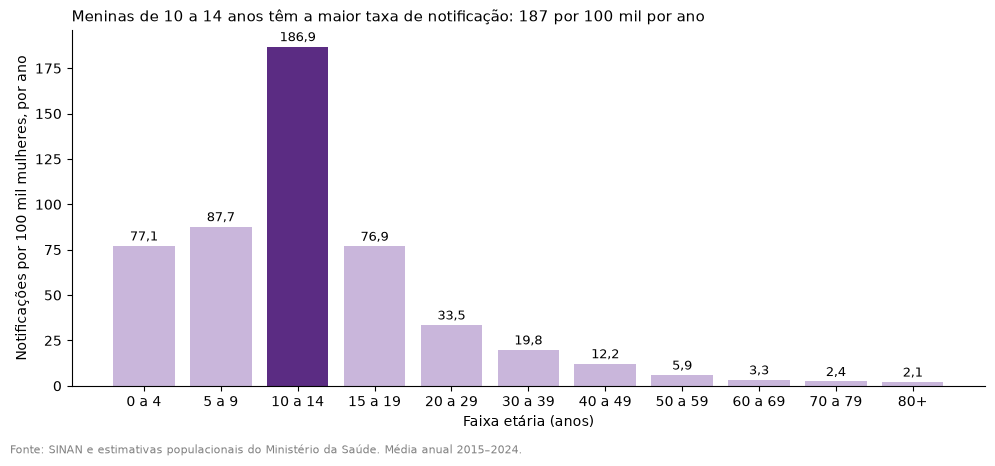

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))

cores_barras = ["#5B2C83" if f == "10 a 14 anos" else "#C9B6DB" for f in tabela_p3.index]
ax.bar(range(len(tabela_p3)), tabela_p3["taxa_100mil"], color=cores_barras)

for i, v in enumerate(tabela_p3["taxa_100mil"]):
    ax.text(i, v + 3, f"{v:.1f}".replace(".", ","), ha="center", fontsize=9)

ax.set_xticks(range(len(tabela_p3)), [f.replace(" anos", "").replace(" e mais", "+") for f in tabela_p3.index])
ax.set_title("Meninas de 10 a 14 anos têm a maior taxa de notificação: 187 por 100 mil por ano",
             loc="left", fontsize=11)
ax.set_xlabel("Faixa etária (anos)")
ax.set_ylabel("Notificações por 100 mil mulheres, por ano")
ax.spines[["top", "right"]].set_visible(False)

fig.text(0.01, -0.02, "Fonte: SINAN e estimativas populacionais do Ministério da Saúde. Média anual 2015–2024.",
         fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("../figures/p3_taxa_idade.png", dpi=200, bbox_inches="tight")
plt.show()

**O que o gráfico mostra.** Ao considerar o tamanho de cada grupo na população, a concentração na infância e no início da adolescência fica ainda mais clara. A faixa de 10 a 14 anos tem 186,9 notificações por 100 mil meninas por ano, mais que o dobro das faixas vizinhas (87,7 entre 5 e 9 anos e 76,9 entre 15 e 19). A partir dos 20 anos, a taxa cai rapidamente: 33,5 entre 20 e 29 anos e menos de 6 a partir dos 50.

**Como interpretar.** Parte da diferença pode refletir onde a notificação acontece: crianças e adolescentes passam por serviços (escola, conselho tutelar, unidades de saúde) que identificam e notificam a violência, enquanto mulheres adultas podem procurar diretamente a polícia ou não procurar atendimento. Ainda assim, a magnitude da taxa entre 10 e 14 anos aponta esse grupo como prioritário para prevenção.

### Taxa por cor/raça

Como a população feminina por cor/raça só existe no Censo, usamos a população de 2022 (IBGE, SIDRA 9606) e a média anual de notificações de 2021 a 2023. Notificações com cor/raça ignorada (4,5% nesse período) ficam de fora da taxa.

In [12]:
pop_raca = pd.read_csv("../data/processed/pop_feminina_raca_censo2022.csv", sep=";", index_col="cor_raca")

notif_raca = (sinan[sinan["ANO"].between(2021, 2023)]["RACA"].value_counts() / 3).reindex(pop_raca.index)

tabela_raca = pd.DataFrame({
    "notificacoes_ano": notif_raca.round(0),
    "pop_feminina_2022": pop_raca["pop_feminina_2022"],
    "taxa_100mil": (notif_raca / pop_raca["pop_feminina_2022"] * 100_000).round(1),
}).sort_values("taxa_100mil")

# mulheres negras = pretas + pardas
negras = (notif_raca[["Preta", "Parda"]].sum() / pop_raca.loc[["Preta", "Parda"], "pop_feminina_2022"].sum() * 100_000)
print(f"Taxa mulheres negras (pretas + pardas): {negras:.1f}  |  brancas: {tabela_raca.loc['Branca', 'taxa_100mil']}")
tabela_raca

Taxa mulheres negras (pretas + pardas): 55.4  |  brancas: 40.7


,notificacoes_ano,pop_feminina_2022,taxa_100mil
cor_raca,,,
Branca,18925.0,46463555,40.7
Preta,5326.0,10130438,52.6
Parda,26246.0,46883709,56.0
Amarela,491.0,449273,109.2
Indígena,748.0,616574,121.4


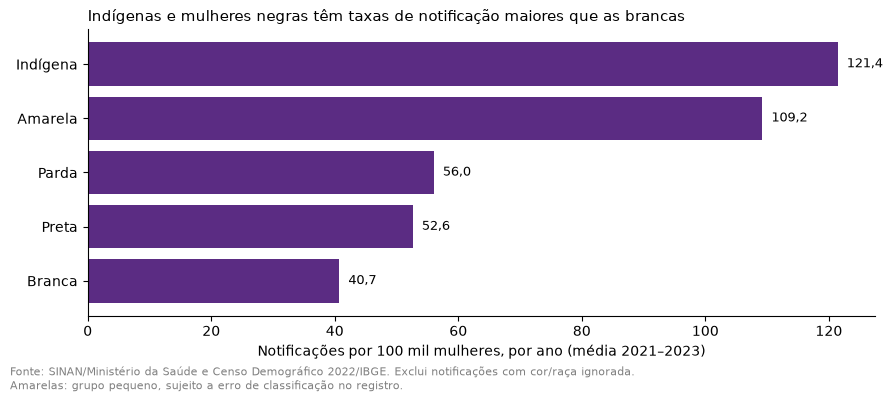

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.8))

ax.barh(tabela_raca.index, tabela_raca["taxa_100mil"], color="#5B2C83")
for i, v in enumerate(tabela_raca["taxa_100mil"]):
    ax.text(v + 1.5, i, f"{v:.1f}".replace(".", ","), va="center", fontsize=9)

ax.set_title("Indígenas e mulheres negras têm taxas de notificação maiores que as brancas",
             loc="left", fontsize=11)
ax.set_xlabel("Notificações por 100 mil mulheres, por ano (média 2021–2023)")
ax.spines[["top", "right"]].set_visible(False)

fig.text(0.01, -0.04,
         "Fonte: SINAN/Ministério da Saúde e Censo Demográfico 2022/IBGE. Exclui notificações com cor/raça ignorada.\n"
         "Amarelas: grupo pequeno, sujeito a erro de classificação no registro.",
         fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("../figures/p3_taxa_raca.png", dpi=200, bbox_inches="tight")
plt.show()

**O que o gráfico mostra.** Mulheres pretas (52,6 por 100 mil por ano) e pardas (56,0) têm taxas de notificação maiores que as brancas (40,7). Somadas, as mulheres negras chegam a 55,4, cerca de 1,4 vez a taxa das brancas. As maiores taxas são das indígenas (121,4), quase três vezes a das brancas.

**Cuidados.** Estas são taxas brutas: grupos com população mais jovem, como as indígenas, tendem a ter taxas maiores simplesmente porque a violência sexual notificada se concentra na infância e na adolescência. Na versão final, vamos padronizar as taxas por idade. A taxa das amarelas (109,2) deve ser lida com cautela: o grupo é pequeno (0,4% da população feminina) e há registros em que a categoria é marcada por engano, o que pode inflar o número de notificações.

### Deficiência e transtornos

A ficha do SINAN registra se a vítima tem deficiência (física, intelectual, visual, auditiva) ou transtorno (mental ou de comportamento). Essa definição é mais ampla que a do Censo e muda conforme a idade, por isso, nesta etapa, olhamos a **proporção de vítimas** com cada condição em cada faixa etária, em vez de uma taxa populacional.

In [14]:
tipos = {
    "DEF_MENTAL": "Deficiência intelectual",
    "DEF_FISICA": "Deficiência física",
    "DEF_VISUAL": "Deficiência visual",
    "DEF_AUDITI": "Deficiência auditiva",
    "TRAN_MENT": "Transtorno mental",
    "TRAN_COMP": "Transtorno de comportamento",
}

# só notificações em que o campo deficiência/transtorno foi preenchido (Sim ou Não)
pd_def = sinan[sinan["DEFICIENCIA"] != "Ignorado"].copy()
for col in tipos:
    pd_def[col] = limpa_codigo(pd_def[col]).eq("1")

pct_tipo = (pd_def.groupby("FAIXA", observed=True)[list(tipos)].mean() * 100).rename(columns=tipos).T.round(1)
pct_alguma = (pd_def.groupby("FAIXA", observed=True)["DEFICIENCIA"].apply(lambda x: (x == "Sim").mean() * 100)).round(1)

print("% de vítimas com alguma deficiência ou transtorno, por faixa:")
print(pct_alguma.to_string())
pct_tipo

% de vítimas com alguma deficiência ou transtorno, por faixa:
FAIXA
0 a 13 anos         5.0
14 a 17 anos       10.3
18 anos ou mais    16.1


FAIXA,0 a 13 anos,14 a 17 anos,18 anos ou mais
Deficiência intelectual,1.3,3.0,4.2
Deficiência física,0.3,0.5,1.3
Deficiência visual,0.2,0.3,0.7
Deficiência auditiva,0.1,0.3,0.7
Transtorno mental,1.6,4.4,8.4
Transtorno de comportamento,1.4,2.9,3.7


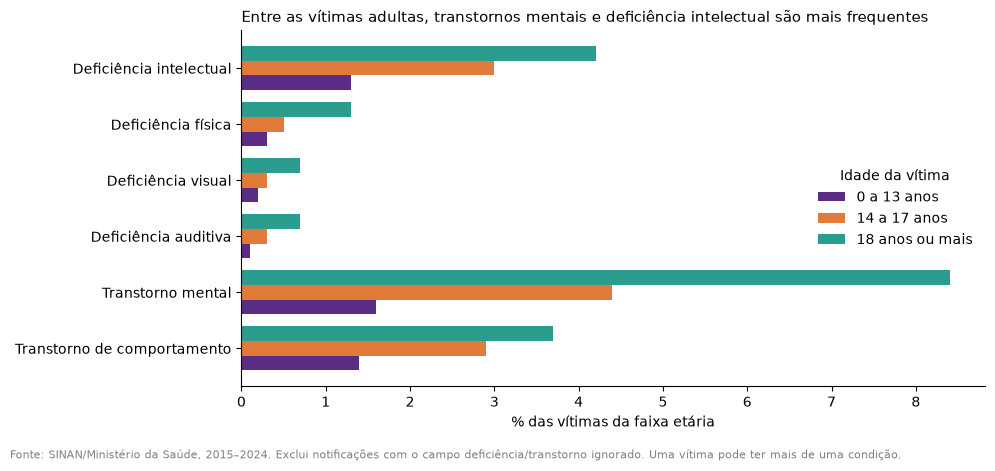

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.5))

cores = {"0 a 13 anos": "#5B2C83", "14 a 17 anos": "#E07B39", "18 anos ou mais": "#2A9D8F"}
y = np.arange(len(pct_tipo))
altura = 0.26
for k, (faixa, cor) in enumerate(cores.items()):
    ax.barh(y + (1 - k) * altura, pct_tipo[faixa], height=altura, color=cor, label=faixa)

ax.set_yticks(y, pct_tipo.index)
ax.invert_yaxis()
ax.set_title("Entre as vítimas adultas, transtornos mentais e deficiência intelectual são mais frequentes",
             loc="left", fontsize=11)
ax.set_xlabel("% das vítimas da faixa etária")
ax.legend(frameon=False, title="Idade da vítima", loc="center right")
ax.spines[["top", "right"]].set_visible(False)

fig.text(0.01, -0.03,
         "Fonte: SINAN/Ministério da Saúde, 2015–2024. Exclui notificações com o campo deficiência/transtorno ignorado. "
         "Uma vítima pode ter mais de uma condição.",
         fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("../figures/p3_deficiencia.png", dpi=200, bbox_inches="tight")
plt.show()

**O que o gráfico mostra.** Entre as notificações com o campo preenchido, 5,0% das vítimas de 0 a 13 anos tinham alguma deficiência ou transtorno, proporção que sobe para 10,3% entre 14 e 17 anos e 16,1% entre adultas. As condições mais frequentes são o transtorno mental (8,4% das vítimas adultas) e a deficiência intelectual (4,2%). Deficiências física, visual e auditiva aparecem em menos de 1,5% dos casos em todas as faixas.

**Como interpretar.** Deficiência intelectual e transtornos mentais podem aumentar a vulnerabilidade, porque dificultam reconhecer a violência, pedir ajuda ou ser ouvida, e aumentam a dependência de cuidadores. Entre crianças, a proporção menor pode refletir, em parte, que essas condições ainda não foram diagnosticadas. Como a definição do SINAN é mais ampla que a do Censo e a prevalência de deficiência muda muito com a idade, nesta etapa não calculamos uma taxa populacional; o campo também tem 11,5% de respostas ignoradas.

### Síntese da pergunta 3

As notificações se concentram em meninas: mais da metade das vítimas tem menos de 14 anos, e a taxa entre 10 e 14 anos (187 por 100 mil por ano) é a mais alta de todas as faixas. Mulheres negras e indígenas têm taxas maiores que as brancas, e cerca de uma em cada seis vítimas adultas tem alguma deficiência ou transtorno. Próximos passos para a versão final: padronizar as taxas por cor/raça pela idade e usar os dados do Censo sobre deficiência por faixa etária para calcular taxas comparáveis.